# Demand forecast · Redwood Auto Group

**Business question:** how many customers will want each type of vehicle in the next three months, and is the current way of ordering stock good enough?

**Approach**
1. Look at demand (leads) by segment: trend and seasonality.
2. Build four forecasting models, from the dealership's current rule to Holt-Winters.
3. **Backtest** them: each model forecasts months it never saw, and we measure the error.
4. Pick the most accurate model per segment and forecast **Oct – Dec 2026**, with a likely range.
5. Convert leads into expected sales and export the results for the dashboard and for inventory planning.
6. Turn the forecast into an **order plan** and compare it with the current rule, in units and dollars.

> Data: synthetic leads for a fictional dealership, Jan 2024 – Sep 2026 (`../data/leads.csv`).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.precision", 1)

SEGMENTS = ["Sedan / compact", "Compact SUV", "Midsize SUV", "Pickup", "Hybrid / EV"]
COLORS = dict(zip(SEGMENTS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
STYLES = dict(zip(SEGMENTS, ["-", "--", ":", "-.", "-"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.edgecolor": "#c3c2b7",
                     "font.size": 10, "legend.frameon": False})

## 1 · Demand by segment

We forecast **leads**, not sales. Leads measure customer interest directly; sales also depend on stock and on the sales team, and the July 2026 pilot raised conversion in every segment. Forecasting sales directly would mistake a process improvement for a jump in demand.

In [2]:
leads = pd.read_csv("../data/leads.csv")
y = (leads.groupby(["month", "segment"]).size().unstack()[SEGMENTS].fillna(0))
y.index = pd.PeriodIndex(y.index, freq="M")
print(f"{len(y)} months: {y.index[0]} to {y.index[-1]}")
y.tail()

33 months: 2024-01 to 2026-09


segment,Sedan / compact,Compact SUV,Midsize SUV,Pickup,Hybrid / EV
month,,,,,
2026-05,143,184,46,93,55
2026-06,121,163,44,92,69
2026-07,132,178,43,89,64
2026-08,133,188,54,87,66
2026-09,124,193,40,85,73


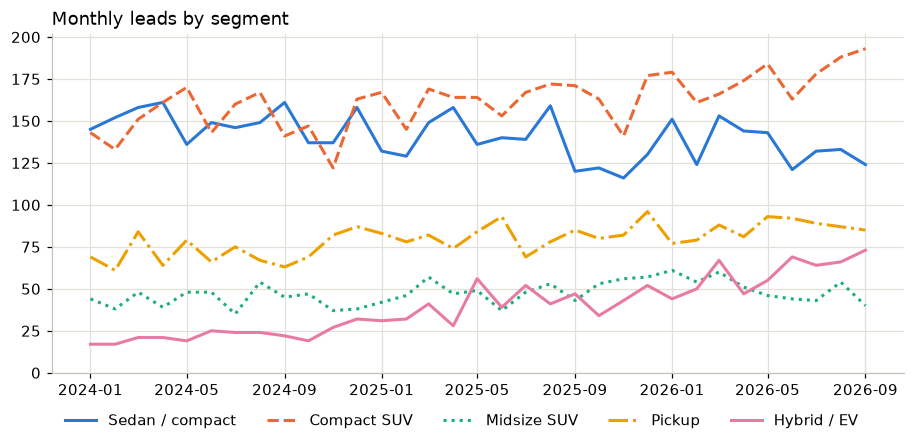

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
for s in SEGMENTS:
    ax.plot(y.index.to_timestamp(), y[s], STYLES[s], color=COLORS[s], lw=2, label=s)
ax.set_title("Monthly leads by segment", loc="left")
ax.set_ylim(0)
ax.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, -0.08))
plt.show()

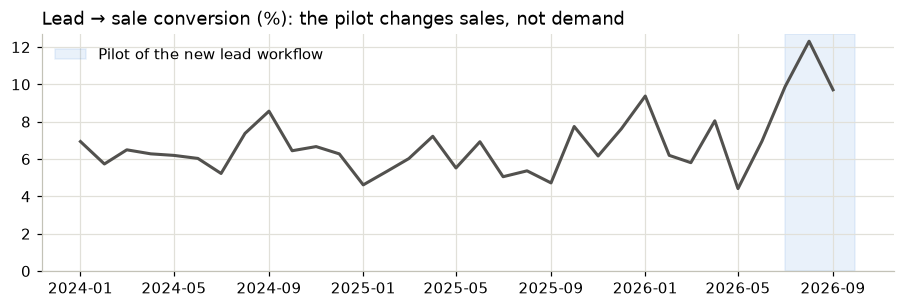

In [4]:
conv = (leads.assign(sold=leads.sale.eq("yes")).groupby("month").sold.mean() * 100)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(pd.PeriodIndex(conv.index, freq="M").to_timestamp(), conv.values, color="#52514e", lw=2)
ax.axvspan(pd.Timestamp("2026-07-01"), pd.Timestamp("2026-09-30"), color="#2a78d6", alpha=0.1, label="Pilot of the new lead workflow")
ax.set_title("Lead → sale conversion (%): the pilot changes sales, not demand", loc="left")
ax.set_ylim(0)
ax.legend(loc="upper left")
plt.show()

## 2 · Trend and seasonality

STL decomposition splits a series into **trend** (long-term direction), **seasonality** (the repeating yearly pattern) and **remainder** (noise). Hybrid / EV shows a strong upward trend; every segment shares a spring and December peak.

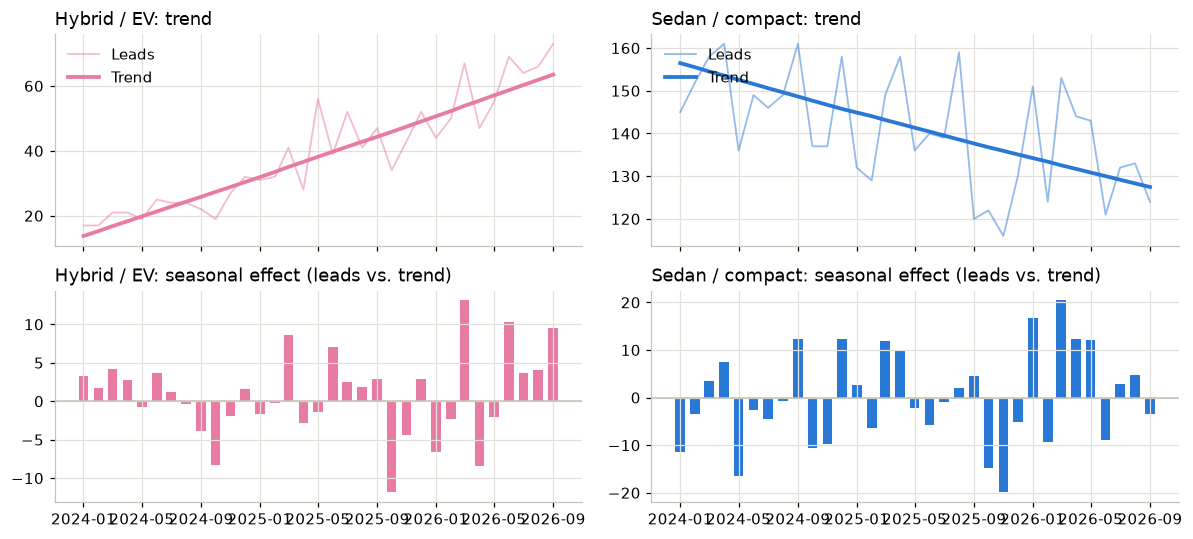

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for col, seg in enumerate(["Hybrid / EV", "Sedan / compact"]):
    res = STL(y[seg].values, period=12, robust=True).fit()
    t = y.index.to_timestamp()
    axes[0, col].plot(t, y[seg], color=COLORS[seg], lw=1.2, alpha=0.5, label="Leads")
    axes[0, col].plot(t, res.trend, color=COLORS[seg], lw=2.5, label="Trend")
    axes[0, col].set_title(f"{seg}: trend", loc="left"); axes[0, col].legend(loc="upper left")
    axes[1, col].bar(t, res.seasonal, width=20, color=COLORS[seg])
    axes[1, col].axhline(0, color="#c3c2b7", lw=1)
    axes[1, col].set_title(f"{seg}: seasonal effect (leads vs. trend)", loc="left")
plt.tight_layout(); plt.show()

## 3 · Four forecasting models

| Model | Idea | Why include it |
|---|---|---|
| **Current rule** | Same month last year + 5% | What the dealership does today: the bar to beat |
| **Last year × growth** | Same month last year × the last 12 months' growth | Adds the trend, nothing else |
| **Holt-Winters** | Exponential smoothing with a damped trend and yearly seasonality | Standard, adapts to recent changes |
| **Regression** | log(leads) = trend + yearly seasonal waves (Fourier terms) | Smooth, few parameters, hard to overfit |

In [6]:
H = 3  # forecast horizon in months

def same_month_last_year(s, h):
    return np.array([s.iloc[-12 + i] for i in range(h)], float)

def current_rule(s, h):
    return same_month_last_year(s, h) * 1.05

def last_year_x_growth(s, h):
    growth = s.iloc[-12:].sum() / s.iloc[-24:-12].sum()
    return same_month_last_year(s, h) * growth

def holt_winters(s, h):
    fit = ExponentialSmoothing(s.values.astype(float), trend="add", damped_trend=True, seasonal="add",
                               seasonal_periods=12, initialization_method="estimated").fit()
    return fit.forecast(h)

def fourier_design(t, k=2):
    cols = [np.ones_like(t, float), t.astype(float)]
    for i in range(1, k + 1):
        cols += [np.sin(2 * np.pi * i * t / 12), np.cos(2 * np.pi * i * t / 12)]
    return np.column_stack(cols)

def regression(s, h):
    t = np.arange(len(s))
    fit = sm.OLS(np.log(s.values + 1), fourier_design(t)).fit()
    return np.exp(fit.predict(fourier_design(np.arange(len(s), len(s) + h)))) - 1

MODELS = {"Current rule (LY +5%)": current_rule, "Last year x growth": last_year_x_growth,
          "Holt-Winters": holt_winters, "Regression": regression}

## 4 · Backtest: how wrong would each model have been?

**Rolling-origin backtest:** pretend it is the end of Dec 2025, train on everything up to then, forecast the next 3 months and compare with what actually happened. Then move forward one month and repeat, up to Jun 2026. Holt-Winters needs two full years to learn seasonality, which is why testing starts in Dec 2025.

Error metric: **WAPE** (weighted absolute percentage error) = total absolute error ÷ total actual leads. 8% means the forecast was off by 8 leads for every 100.

In [7]:
origins = [p for p in y.index if p >= pd.Period("2025-12", "M") and p + H <= y.index[-1]]
rows = []
for seg in SEGMENTS:
    for o in origins:
        train, actual = y.loc[:o, seg], y.loc[o + 1:o + H, seg].values
        for name, model in MODELS.items():
            for h, f in enumerate(model(train, H), start=1):
                rows.append(dict(segment=seg, origin=str(o), horizon=h, model=name, actual=actual[h - 1], forecast=f))
backtest = pd.DataFrame(rows)
backtest["abs_err"] = (backtest.forecast - backtest.actual).abs()
wape = lambda d: d.abs_err.sum() / d.actual.sum() * 100

by_segment = backtest.groupby(["segment", "model"]).apply(wape).unstack()[list(MODELS)].loc[SEGMENTS]
overall = backtest.groupby("model").apply(wape)[list(MODELS)]
print(f"{len(origins)} forecast origins ({origins[0]} to {origins[-1]}) x {H} months x {len(SEGMENTS)} segments")
display(by_segment.round(1).style.format("{:.1f}%").highlight_min(axis=1, color="#cde2fb"))

7 forecast origins (2025-12 to 2026-06) x 3 months x 5 segments


model,Current rule (LY +5%),Last year x growth,Holt-Winters,Regression
segment,,,,
Sedan / compact,10.5%,7.9%,8.0%,7.3%
Compact SUV,3.8%,3.1%,3.1%,6.1%
Midsize SUV,9.2%,13.6%,14.7%,13.4%
Pickup,7.0%,7.3%,6.0%,5.4%
Hybrid / EV,28.9%,21.4%,11.3%,17.6%


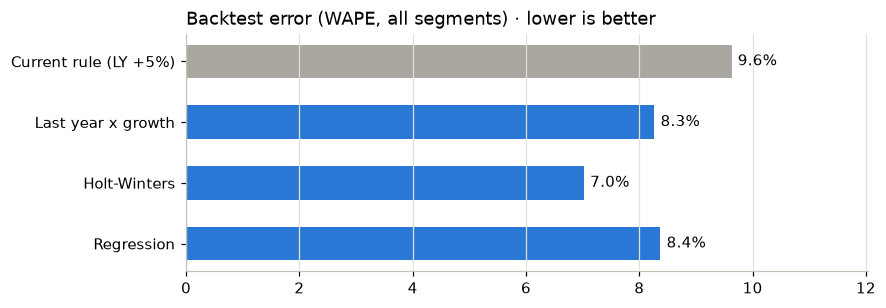

Best overall: Holt-Winters at 7.0% vs 9.6% for the current rule (27% less error).


In [8]:
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(overall.index, overall.values, color=["#a9a79f" if "rule" in m else "#2a78d6" for m in overall.index], height=0.55)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in overall.values], padding=4)
ax.invert_yaxis(); ax.set_xlim(0, overall.max() * 1.25); ax.grid(axis="y", visible=False)
ax.set_title("Backtest error (WAPE, all segments) · lower is better", loc="left")
plt.show()
improvement = 1 - overall.min() / overall["Current rule (LY +5%)"]
print(f"Best overall: {overall.idxmin()} at {overall.min():.1f}% vs {overall['Current rule (LY +5%)']:.1f}% for the current rule "
      f"({improvement:.0%} less error).")

## 5 · Champion model per segment

Each segment keeps the model with the lowest backtest error. Where the simple rule wins (a stable segment), there is no reason to use something more complex.

The **likely range** comes from the backtest itself: the champion's 10th and 90th percentile percentage errors are applied to the forecast. In plain terms, roughly 8 times out of 10 the real number should land inside the range.

In [9]:
champion = by_segment.idxmin(axis=1)
bt_champ = backtest[backtest.model == backtest.segment.map(champion)].copy()
bt_champ["pct_err"] = (bt_champ.actual - bt_champ.forecast) / bt_champ.forecast
bands = bt_champ.groupby("segment").pct_err.quantile([0.1, 0.9]).unstack()
summary = pd.DataFrame({"Champion model": champion, "Champion WAPE": by_segment.min(axis=1),
                        "Current rule WAPE": by_segment["Current rule (LY +5%)"],
                        "Range low": bands[0.1] * 100, "Range high": bands[0.9] * 100}).loc[SEGMENTS]
summary.style.format({"Champion WAPE": "{:.1f}%", "Current rule WAPE": "{:.1f}%", "Range low": "{:+.0f}%", "Range high": "{:+.0f}%"})

,Champion model,Champion WAPE,Current rule WAPE,Range low,Range high
segment,,,,,
Sedan / compact,Regression,7.3%,10.5%,-10%,+14%
Compact SUV,Last year x growth,3.1%,3.8%,-9%,+4%
Midsize SUV,Current rule (LY +5%),9.2%,9.2%,-15%,+13%
Pickup,Regression,5.4%,7.0%,-10%,+4%
Hybrid / EV,Holt-Winters,11.3%,28.9%,-14%,+18%


## 6 · Forecast: Oct – Dec 2026

The champion models are retrained on all 33 months. Leads are converted into expected sales with the **store-wide** lead → sale conversion during the pilot (Jul – Sep 2026), the process the dealership now runs. Per-segment rates over three months are too noisy to use (one segment shows 18% on just 25 sales), so the forecast uses one rate for all.

In [10]:
future = pd.period_range(y.index[-1] + 1, periods=H, freq="M")
pilot = leads[leads.period == "pilot"]
by_seg = pilot.groupby("segment").sale.apply(lambda s: s.eq("yes").mean())
store_rate = pilot.sale.eq("yes").mean()
conversion = pd.Series(store_rate, index=SEGMENTS)
print(f"Store-wide pilot conversion: {store_rate:.1%}  (per segment, for reference: " + ", ".join(f"{k} {v:.1%}" for k, v in by_seg[SEGMENTS].items()) + ")")

out = []
for seg in SEGMENTS:
    fc = np.maximum(MODELS[champion[seg]](y[seg], H), 0)
    rule = current_rule(y[seg], H)
    for i, m in enumerate(future):
        lo, hi = fc[i] * (1 + bands.loc[seg, 0.1]), fc[i] * (1 + bands.loc[seg, 0.9])
        out.append(dict(month=str(m), segment=seg, model=champion[seg],
                        leads_forecast=fc[i], leads_low=max(lo, 0), leads_high=hi, rule_leads=rule[i],
                        conversion=conversion[seg], sales_forecast=fc[i] * conversion[seg],
                        sales_low=max(lo, 0) * conversion[seg], sales_high=hi * conversion[seg]))
forecast = pd.DataFrame(out)
forecast.pivot(index="segment", columns="month", values="leads_forecast").loc[SEGMENTS].round(0)

Store-wide pilot conversion: 10.7%  (per segment, for reference: Sedan / compact 8.2%, Compact SUV 10.7%, Midsize SUV 18.2%, Pickup 10.0%, Hybrid / EV 10.8%)


month,2026-10,2026-11,2026-12
segment,,,
Sedan / compact,123.0,120.0,120.0
Compact SUV,177.0,153.0,192.0
Midsize SUV,56.0,59.0,60.0
Pickup,90.0,97.0,99.0
Hybrid / EV,54.0,62.0,69.0


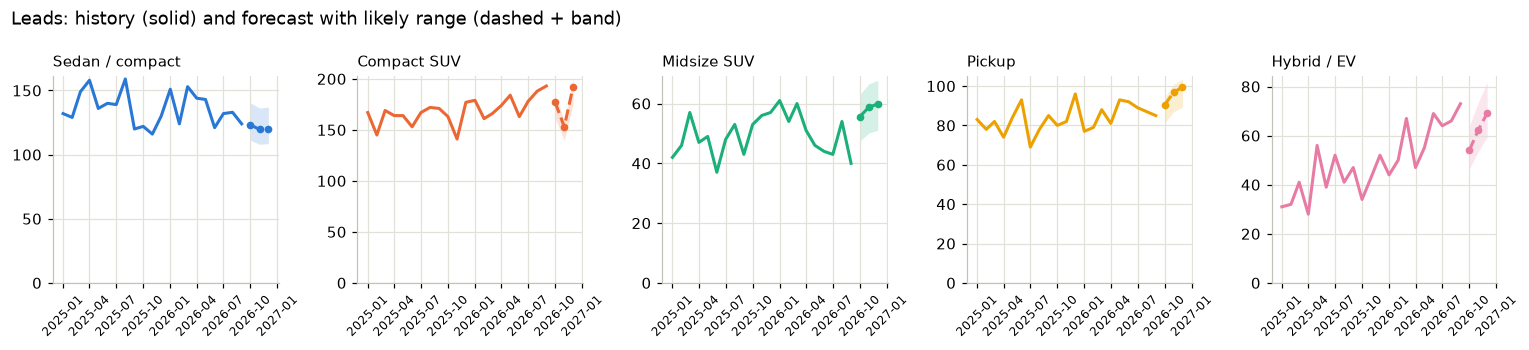

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), sharey=False)
hist_start = pd.Period("2025-01", "M")
for ax, seg in zip(axes, SEGMENTS):
    h = y.loc[hist_start:, seg]
    f = forecast[forecast.segment == seg]
    t_f = pd.PeriodIndex(f.month, freq="M").to_timestamp()
    ax.plot(h.index.to_timestamp(), h.values, color=COLORS[seg], lw=2)
    ax.plot(t_f, f.leads_forecast, color=COLORS[seg], lw=2, ls="--", marker="o", ms=4)
    ax.fill_between(t_f, f.leads_low, f.leads_high, color=COLORS[seg], alpha=0.18, lw=0)
    ax.set_title(seg, loc="left", fontsize=10); ax.set_ylim(0); ax.tick_params(axis="x", labelrotation=45, labelsize=8)
fig.suptitle("Leads: history (solid) and forecast with likely range (dashed + band)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

In [12]:
q = forecast.groupby("segment")[["leads_forecast", "leads_low", "leads_high", "rule_leads", "sales_forecast", "sales_low", "sales_high"]].sum().loc[SEGMENTS]
q["Forecast vs current rule"] = (q.leads_forecast / q.rule_leads - 1) * 100
q.columns = ["Leads", "Leads low", "Leads high", "Current rule", "Sales", "Sales low", "Sales high", "Forecast vs rule"]
print("Next 3 months (Oct – Dec 2026), totals by segment")
q.style.format({c: "{:.0f}" for c in q.columns if c != "Forecast vs rule"} | {"Forecast vs rule": "{:+.0f}%"})

Next 3 months (Oct – Dec 2026), totals by segment


,Leads,Leads low,Leads high,Current rule,Sales,Sales low,Sales high,Forecast vs rule
segment,,,,,,,,
Sedan / compact,363,328,414,386,39,35,44,-6%
Compact SUV,522,476,544,505,56,51,58,+3%
Midsize SUV,174,149,197,174,19,16,21,+0%
Pickup,287,257,299,271,31,27,32,+6%
Hybrid / EV,185,159,219,135,20,17,23,+37%


## 7 · Export for the dashboard and inventory planning

In [13]:
forecast_out = forecast.round({"leads_forecast": 1, "leads_low": 1, "leads_high": 1, "rule_leads": 1, "conversion": 4,
                               "sales_forecast": 1, "sales_low": 1, "sales_high": 1})
backtest_out = (by_segment.stack().rename("wape").reset_index().assign(champion=lambda d: d.model == d.segment.map(champion)).round({"wape": 2}))
# Unix line endings, so the files read the same on every system
forecast_out.to_csv("../data/forecast.csv", index=False, lineterminator="\n")
backtest_out.to_csv("../data/backtest.csv", index=False, lineterminator="\n")
with open("../data/forecast.js", "w", encoding="utf-8", newline="\n") as f:
    f.write("// Generated by 02-demand-forecast/demand_forecast.ipynb - do not edit by hand\n")
    f.write(f"window.FORECAST_CSV = `{forecast_out.to_csv(index=False, lineterminator=chr(10))}`;\n")
    f.write(f"window.BACKTEST_CSV = `{backtest_out.to_csv(index=False, lineterminator=chr(10))}`;\n")
print("Wrote ../data/forecast.csv, ../data/backtest.csv and ../data/forecast.js")

Wrote ../data/forecast.csv, ../data/backtest.csv and ../data/forecast.js


## 8 · From forecast to orders: inventory plan for Oct – Dec 2026

The forecast only matters if it changes what gets ordered. This section compares two ordering plans for the next three months, starting from the stock on the lot at the end of September:

| | How it orders |
|---|---|
| **Current rule** | Last year's average sales for the same 3 months +5% (sedans +20% from factory allocation; hybrids capped at 4 a month) |
| **Forecast plan** | Enough to end each month with **50 days of expected sales** (inside the healthy 45–60 day range), plus a **safety buffer** that covers the high end of the forecast range |

Both plans are then run against the same expected demand. When the lot runs short, **half** of those customers are served with a car borrowed from a sister store (a **transfer**) and **half buy elsewhere** (a **lost sale**). Shortages are the expensive part: a lost sale costs the full gross profit of the car.

**Cost assumptions** (stated so they can be challenged):
- **Holding cost:** about **$400 per car per month** (floorplan interest plus depreciation on a ~$30K vehicle)
- **Transfer cost:** about **$400 per car** (driver, fuel, paperwork)
- **Lost sale:** the average gross profit per car sold in 2026 (vehicle + finance and insurance), about **$3,000**

In [14]:
TARGET_DAYS = 50        # days of supply to aim for at the end of each month
MIN_STOCK = 2           # below this, cars are borrowed from sister stores
HOLDING_COST = 400      # $ per car per month on the lot
TRANSFER_COST = 400     # $ per car borrowed from a sister store
LOST_SHARE = 0.5        # share of short customers who buy elsewhere instead of waiting for a transfer
GROSS_PER_CAR = leads[(leads.month >= "2026-01") & leads.sale.eq("yes")].gross_profit_usd.mean()
RULE_FACTOR = {"Sedan / compact": 1.20}   # factory push on sedans; everything else +5%
HYBRID_CAP = 4

inv = pd.read_csv("../data/inventory.csv")
inv["month"] = pd.PeriodIndex(inv.month, freq="M")
sold = inv.pivot(index="month", columns="segment", values="sold")[SEGMENTS]
stock_now = inv[inv.month == inv.month.max()].set_index("segment").loc[SEGMENTS, ["closing_stock", "days_supply"]]
print(f"Stock at the end of {inv.month.max()}:")
stock_now.rename(columns={"closing_stock": "Cars in stock", "days_supply": "Days of supply"})

Stock at the end of 2026-09:


,Cars in stock,Days of supply
segment,,
Sedan / compact,50,155.0
Compact SUV,2,3.0
Midsize SUV,2,8.0
Pickup,2,8.0
Hybrid / EV,2,8.0


In [15]:
def rule_orders(seg):
    orders = []
    for m in future:
        ly3 = sold.loc[m - 13:m - 11, seg].mean()
        q = round(ly3 * RULE_FACTOR.get(seg, 1.05))
        orders.append(min(q, HYBRID_CAP) if seg == "Hybrid / EV" else q)
    return orders

def forecast_orders(seg, open_stock):
    f = forecast[forecast.segment == seg]
    avg_sales = f.sales_forecast.mean()
    orders, stock = [], open_stock
    for _, r in f.iterrows():
        target = TARGET_DAYS / 30 * avg_sales + (r.sales_high - r.sales_forecast)   # cover + safety buffer
        q = max(0, round(target + r.sales_forecast - stock))
        orders.append(q)
        stock = stock + q - r.sales_forecast
    return orders

def simulate(seg, orders, open_stock):
    f = forecast[forecast.segment == seg].reset_index(drop=True)
    rows, stock = [], open_stock
    for i, r in f.iterrows():
        opening = stock
        stock = opening + orders[i] - r.sales_forecast
        short = max(0, MIN_STOCK - stock)          # customers the lot cannot serve
        transfers, lost = short * (1 - LOST_SHARE), short * LOST_SHARE
        stock += short                             # stock floor: borrowed cars are replaced, lost customers never needed a car
        rows.append(dict(month=r.month, segment=seg, opening=opening, order=orders[i], expected_sales=r.sales_forecast,
                         transfers=transfers, lost_sales=lost, closing=stock, days_supply=stock / f.sales_forecast.mean() * 30,
                         holding_cost=(opening + stock) / 2 * HOLDING_COST, transfer_cost=transfers * TRANSFER_COST,
                         lost_gross=lost * GROSS_PER_CAR))
    return rows

plan_rows = []
for seg in SEGMENTS:
    s0 = stock_now.loc[seg, "closing_stock"]
    for plan, orders in [("Current rule", rule_orders(seg)), ("Forecast plan", forecast_orders(seg, s0))]:
        plan_rows += [dict(r, plan=plan) for r in simulate(seg, orders, s0)]
plan = pd.DataFrame(plan_rows)

summary_plan = (plan.groupby(["segment", "plan"])
                .agg(orders=("order", "sum"), transfers=("transfers", "sum"), lost_sales=("lost_sales", "sum"), end_stock=("closing", "last"),
                     end_days=("days_supply", "last"), holding=("holding_cost", "sum"), transfer_cost=("transfer_cost", "sum"), lost_gross=("lost_gross", "sum"))
                .assign(total_cost=lambda d: d.holding + d.transfer_cost + d.lost_gross)
                .reindex(pd.MultiIndex.from_product([SEGMENTS, ["Current rule", "Forecast plan"]])))
print(f"Gross profit per car used for lost sales: ${GROSS_PER_CAR:,.0f}")
summary_plan.style.format({"orders": "{:.0f}", "transfers": "{:.0f}", "lost_sales": "{:.0f}", "end_stock": "{:.0f}", "end_days": "{:.0f}",
                           "holding": "${:,.0f}", "transfer_cost": "${:,.0f}", "lost_gross": "${:,.0f}", "total_cost": "${:,.0f}"})

Gross profit per car used for lost sales: $2,978


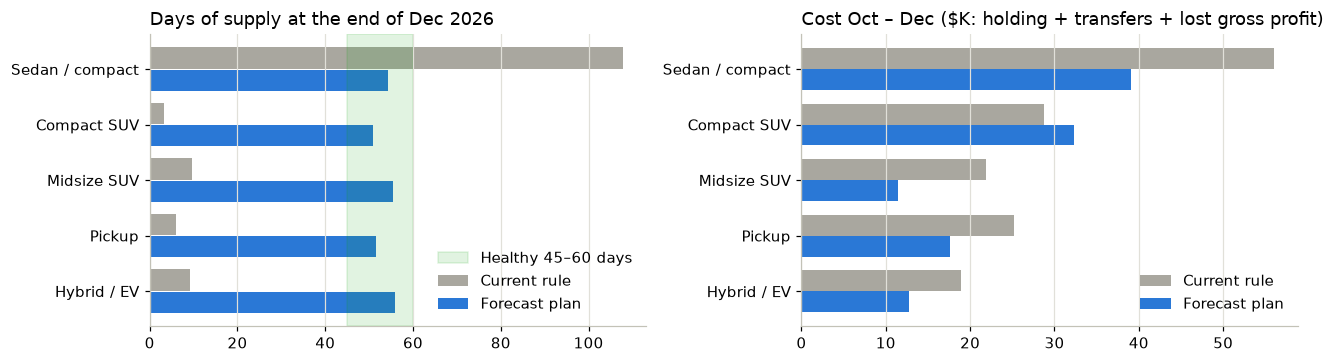

Current rule: 109 cars ordered, 25 transfers, 25 lost sales, total cost $150,925
Forecast plan: 201 cars ordered, 0 transfers, 0 lost sales, total cost $113,243
Difference over the quarter: $37,682 (about $150,730 a year if repeated every quarter)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
ends = summary_plan.end_days.unstack()[["Current rule", "Forecast plan"]].loc[SEGMENTS]
y_pos = np.arange(len(SEGMENTS))
for ax, col, color in [(axes[0], "Current rule", "#a9a79f"), (axes[0], "Forecast plan", "#2a78d6")]:
    off = -0.2 if col == "Current rule" else 0.2
    bars = ax.barh(y_pos + off, ends[col].clip(upper=200), height=0.38, color=color, label=col)
axes[0].axvspan(45, 60, color="#0ca30c", alpha=0.12, label="Healthy 45–60 days")
axes[0].set_yticks(y_pos, SEGMENTS); axes[0].invert_yaxis(); axes[0].grid(axis="y", visible=False)
axes[0].set_title("Days of supply at the end of Dec 2026", loc="left"); axes[0].legend(loc="lower right")

cost = summary_plan.total_cost.unstack()[["Current rule", "Forecast plan"]].loc[SEGMENTS] / 1000
cost.plot.barh(ax=axes[1], color=["#a9a79f", "#2a78d6"], width=0.75)
axes[1].invert_yaxis(); axes[1].grid(axis="y", visible=False); axes[1].set_ylabel("")
axes[1].set_title("Cost Oct – Dec ($K: holding + transfers + lost gross profit)", loc="left"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

tot = summary_plan.groupby(level=1)[["orders", "transfers", "lost_sales", "total_cost"]].sum()
saving = tot.loc["Current rule", "total_cost"] - tot.loc["Forecast plan", "total_cost"]
for p_ in ["Current rule", "Forecast plan"]:
    print(f"{p_}: {tot.loc[p_,'orders']:.0f} cars ordered, {tot.loc[p_,'transfers']:.0f} transfers, {tot.loc[p_,'lost_sales']:.0f} lost sales, total cost ${tot.loc[p_,'total_cost']:,.0f}")
print(f"Difference over the quarter: ${saving:,.0f} (about ${saving * 4:,.0f} a year if repeated every quarter)")

In [17]:
plan_out = plan.round({"opening": 1, "order": 0, "expected_sales": 1, "transfers": 1, "closing": 1, "days_supply": 0, "holding_cost": 0, "transfer_cost": 0, "lost_sales": 1, "lost_gross": 0})
plan_out["month"] = plan_out["month"].astype(str)
stock_out = stock_now.reset_index().rename(columns={"index": "segment"})
plan_out.to_csv("../data/inventory_plan.csv", index=False, lineterminator="\n")
with open("../data/inventory_plan.js", "w", encoding="utf-8", newline="\n") as f:
    f.write("// Generated by 02-demand-forecast/demand_forecast.ipynb - do not edit by hand\n")
    f.write(f"window.PLAN_CSV = `{plan_out.to_csv(index=False, lineterminator=chr(10))}`;\n")
    f.write(f"window.PLAN_ASSUMPTIONS = {{ targetDays: {TARGET_DAYS}, holdingCost: {HOLDING_COST}, transferCost: {TRANSFER_COST}, lostShare: {LOST_SHARE}, grossPerCar: {GROSS_PER_CAR:.0f}, minStock: {MIN_STOCK} }};\n")
print("Wrote ../data/inventory_plan.csv and ../data/inventory_plan.js")

Wrote ../data/inventory_plan.csv and ../data/inventory_plan.js


## Limitations

- **Short history.** 33 months is enough to learn one yearly pattern, not to test it many times; the backtest has 7 origins. Real deployments should re-run the backtest every month and watch the error.
- **Synthetic data.** The trends were built into the data on purpose; the method, not the numbers, is the point.
- **Conversion is held constant** at the store-wide pilot level (10.7%) for every segment; with more months, segment-specific rates become reliable. If the sales process changes again, the sales forecast must be updated even if the leads forecast is right.
- **No external drivers yet** (interest rates, gas prices, model launches). They are a natural next step for the regression model.
- **Inventory plan simplifications:** orders are assumed to arrive within the month; sales are timed by the month the lead arrived (sales close within about two weeks); costs are round-number assumptions. Excess sedans can only be cleared by not ordering, so the plan shows how fast stock returns to the healthy range, not a fire sale.